# Zeladoria do bairro: o que os dados do SP156 dizem sobre os problemas da rua

**Global Solution 2026.2 · FIAP · Engenharia de Software · Data Science & Statistical Computing**

| Integrante | RM |
|---|---|
| Anthony Gonçalves Sforzin | 562096 |
| Cesar Aaron Herrera | 565398 |

**CitizenTech:** plataforma em que o morador registra problemas da rua (buraco, entulho, bueiro, calçada), apoia os registros dos vizinhos e acompanha o atendimento. Do outro lado, a subprefeitura recebe uma fila priorizada pelo impacto nas pessoas. Território observado: Rua Barão de Iguape, Liberdade (Subprefeitura Sé), São Paulo.

## 1. Contexto, perguntas e variáveis-alvo

Hoje o morador abre um pedido no SP156 e fica sem saber quando ele será atendido, e a subprefeitura não sabe com antecedência quantos pedidos vão chegar. Usamos os dados públicos de **todas as solicitações de zeladoria feitas em 2025 na cidade de São Paulo** para responder a duas perguntas:

| # | Pergunta | Tipo | Variável-alvo |
|---|---|---|---|
| 1 | **Quantos pedidos de zeladoria cada subprefeitura vai receber amanhã?** Serve para dimensionar as equipes de campo. | Regressão linear | `n`: número de pedidos abertos no dia, por subprefeitura (numérica) |
| 2 | **Este pedido corre risco de não ser resolvido em até 7 dias?** Serve para avisar o cidadão e para o gestor agir antes do atraso. | Regressão logística | `atraso`: 1 se o pedido **não** foi finalizado em até 7 dias, 0 se foi (binária) |

**Por que 7 dias:** é um prazo curto e fácil de comunicar ao cidadão ("uma semana"), e é o indicador de impacto da nossa CitizenTech (% de ocorrências resolvidas em até 7 dias).

**Hipótese que vamos testar:** quando muitos pedidos do mesmo tipo chegam à mesma subprefeitura na semana anterior (fila cheia), o risco de atraso aumenta.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, accuracy_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
AZUL, VERMELHO, AMARELO, VERDE = "#1A4D8F", "#C8102E", "#F2C200", "#1E7D4F"

## 2. Os dados

**Fonte:** Portal de Dados Abertos da Prefeitura de São Paulo, conjunto **"Dados do SP156"**, licença CC0 (uso livre): <https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156>. Usamos os arquivos dos 4 trimestres de 2025.

A base original não tem dados pessoais de quem pediu (a prefeitura já os remove). O script `preparar_base.py`, que acompanha este notebook:
- junta os 4 trimestres;
- mantém só os temas de zeladoria ("Rua e bairro" e "Lixo e limpeza") e os assuntos de manutenção física da rua (tira poluição sonora, fiscalização de ambulantes etc.);
- padroniza nomes antigos e mantém só as **32 subprefeituras** (tira órgãos como "Superintendência das Usinas de Asfalto", que somam menos de 0,5% dos pedidos);
- descarta o endereço;
- salva o arquivo `dados/sp156_zeladoria_2025.csv.gz` (no ZIP da entrega vai a versão `.csv`, sem compactação).

| Coluna | Significado |
|---|---|
| `data_abertura` | Dia em que o cidadão abriu o pedido |
| `data_finalizacao` | Dia em que o órgão finalizou o pedido (vazio se ainda aberto) |
| `meio` | Canal usado: PORTAL, MOBILE (aplicativo), CRM (telefone 156), CHATBOT |
| `assunto` | Tipo de problema (entulho, asfalto, calçadas, drenagem...) |
| `status` | Situação na data em que a prefeitura gerou o arquivo |
| `subprefeitura`, `distrito` | Onde fica o problema |

In [2]:
from pathlib import Path

# No repositorio a base esta compactada (.csv.gz); no ZIP da entrega vai o .csv
arquivo = Path("dados/sp156_zeladoria_2025.csv")
if not arquivo.exists():
    arquivo = Path("dados/sp156_zeladoria_2025.csv.gz")
dados = pd.read_csv(arquivo, parse_dates=["data_abertura", "data_finalizacao"])
print(f"{len(dados):,} pedidos de zeladoria em 2025")
dados.head()

507,859 pedidos de zeladoria em 2025


,data_abertura,data_finalizacao,meio,assunto,status,subprefeitura,distrito
0,2025-01-01,2025-01-06,MOBILE,Capinação e roçada de áreas verdes,Finalizada,JACANA-TREMEMBE,TREMEMBE
1,2025-01-01,2025-01-03,CRM,Coleta de lixo domiciliar,Finalizada,PENHA,PENHA
2,2025-01-01,2025-01-03,CRM,Coleta de lixo domiciliar,Finalizada,SE,BELA VISTA
3,2025-01-01,2025-01-02,MOBILE,Drenagem de água de chuva,Finalizada,SE,SANTA CECILIA
4,2025-01-01,2025-01-03,PORTAL,Coleta seletiva,Finalizada,LAPA,JAGUARE


In [3]:
print("Valores ausentes por coluna:")
print(dados.isna().sum())
print()
print(dados["status"].value_counts())

Valores ausentes por coluna:
data_abertura           0
data_finalizacao    25622
meio                    0
assunto                 0
status                  0
subprefeitura           0
distrito                1
dtype: int64

status
Finalizada      479909
Aberto           25435
Cancelada         2413
Em Andamento       102
Name: count, dtype: int64


`data_finalizacao` vazia é esperada: corresponde aos pedidos ainda abertos ou cancelados. Os arquivos de 2025 foram gerados pela prefeitura em 2026, então **todo pedido de 2025 ainda aberto já passou de 7 dias**. Isso nos permite rotular esses pedidos como "atraso" sem distorção.

Os pedidos **cancelados** (pelo próprio cidadão) saem da análise do prazo, porque não dizem nada sobre a eficiência do atendimento.

In [4]:
dados["dias_ate_finalizar"] = (dados["data_finalizacao"] - dados["data_abertura"]).dt.days
dados["dia_semana"] = dados["data_abertura"].dt.day_name(locale=None).map({
    "Monday": "seg", "Tuesday": "ter", "Wednesday": "qua", "Thursday": "qui",
    "Friday": "sex", "Saturday": "sab", "Sunday": "dom"})

finalizados = dados[dados["status"] == "Finalizada"]
print("Dias até finalizar (pedidos finalizados):")
print(finalizados["dias_ate_finalizar"].describe().round(1))

Dias até finalizar (pedidos finalizados):
count    479824.0
mean         16.6
std          47.6
min           0.0
25%           1.0
50%           2.0
75%           8.0
max         571.0
Name: dias_ate_finalizar, dtype: float64


## 3. Análise exploratória

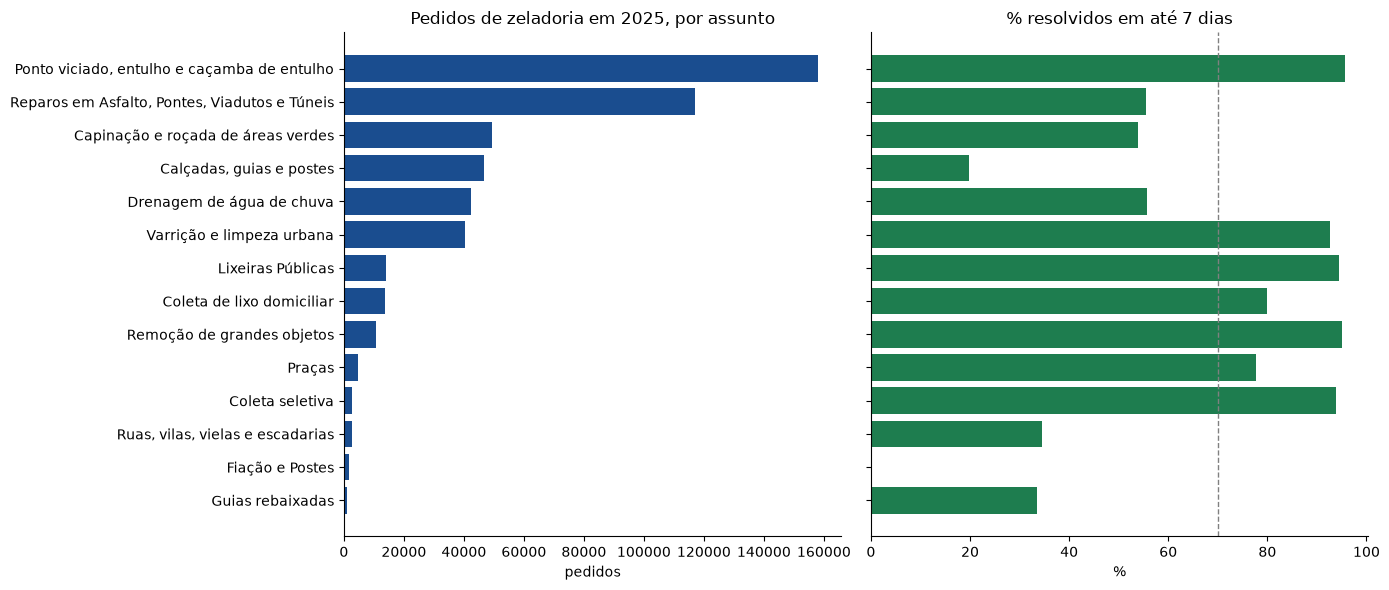

In [5]:
por_assunto = (dados[dados["status"] != "Cancelada"]
               .assign(no_prazo=lambda d: (d["status"] == "Finalizada") & (d["dias_ate_finalizar"] <= 7))
               .groupby("assunto")
               .agg(pedidos=("no_prazo", "size"), pct_resolvido_7d=("no_prazo", "mean"))
               .sort_values("pedidos"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
a1.barh(por_assunto.index, por_assunto["pedidos"], color=AZUL)
a1.set_title("Pedidos de zeladoria em 2025, por assunto")
a1.set_xlabel("pedidos")
a2.barh(por_assunto.index, por_assunto["pct_resolvido_7d"] * 100, color=VERDE)
a2.axvline(70, color="gray", linestyle="--", linewidth=1)
a2.set_title("% resolvidos em até 7 dias")
a2.set_xlabel("%")
plt.tight_layout()
plt.show()

**Leitura dos gráficos:**
- **Entulho** e **asfalto (tapa-buraco)** dominam o volume de pedidos.
- O tempo de resposta varia muito entre os assuntos. Os pedidos de limpeza (entulho, varrição) costumam ser resolvidos em poucos dias, mas reparos como **calçadas e guias** e **drenagem** demoram bem mais. A linha tracejada marca 70%, perto da média geral.

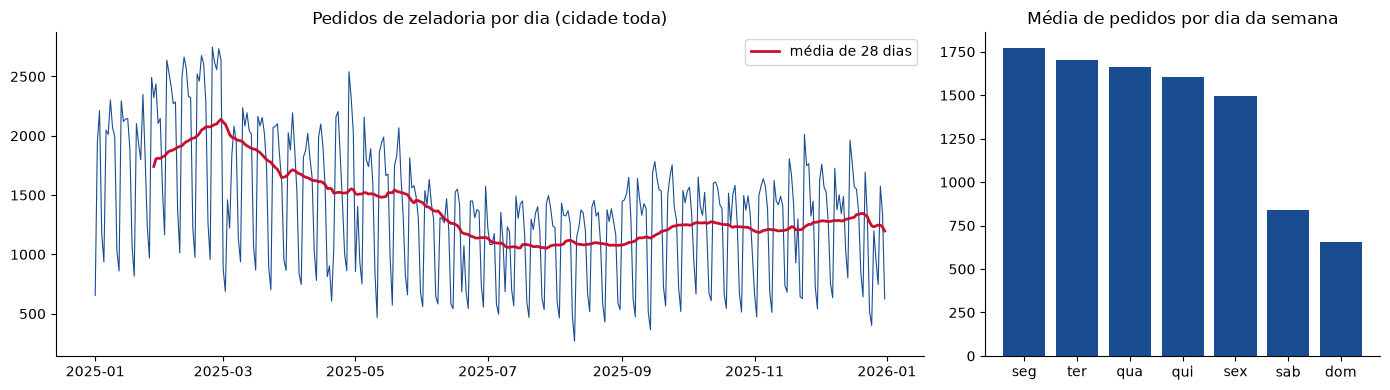

In [6]:
diario_cidade = dados.groupby("data_abertura").size()
media_dia_semana = (diario_cidade.groupby(diario_cidade.index.day_of_week).mean()
                    .rename(index=dict(enumerate(["seg", "ter", "qua", "qui", "sex", "sab", "dom"]))))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
a1.plot(diario_cidade.index, diario_cidade.values, color=AZUL, linewidth=0.8)
a1.plot(diario_cidade.rolling(28).mean(), color=VERMELHO, linewidth=2, label="média de 28 dias")
a1.set_title("Pedidos de zeladoria por dia (cidade toda)")
a1.legend()
a2.bar(media_dia_semana.index, media_dia_semana.values, color=AZUL)
a2.set_title("Média de pedidos por dia da semana")
plt.tight_layout()
plt.show()

A demanda tem um **ciclo semanal forte**: muito mais pedidos nos dias úteis do que no fim de semana. Por isso, o dia da semana e os valores dos dias anteriores devem ajudar a prever a demanda de amanhã.

In [7]:
sub = (dados[dados["status"] != "Cancelada"]
       .assign(no_prazo=lambda d: (d["status"] == "Finalizada") & (d["dias_ate_finalizar"] <= 7))
       .groupby("subprefeitura")
       .agg(pedidos=("no_prazo", "size"), pct_resolvido_7d=("no_prazo", "mean"))
       .sort_values("pct_resolvido_7d"))
print("Subprefeituras com MENOR % de pedidos resolvidos em até 7 dias:")
print(sub.head(5).round(3))
print()
print("Subprefeituras com MAIOR %:")
print(sub.tail(5).round(3))
print()
print("Sé (onde fica a Liberdade):")
print(sub.loc[["SE"]].round(3))

Subprefeituras com MENOR % de pedidos resolvidos em até 7 dias:
                  pedidos  pct_resolvido_7d
subprefeitura                              
PINHEIROS           13270             0.561
PIRITUBA-JARAGUA    23824             0.563
ITAIM PAULISTA      14888             0.588
BUTANTA             25188             0.600
ITAQUERA            26694             0.638

Subprefeituras com MAIOR %:
                           pedidos  pct_resolvido_7d
subprefeitura                                       
ERMELINO MATARAZZO            7787             0.766
GUAIANASES                    9505             0.782
VILA PRUDENTE                 9988             0.789
VILA MARIA-VILA GUILHERME    16386             0.806
JABAQUARA                    12972             0.874

Sé (onde fica a Liberdade):
               pedidos  pct_resolvido_7d
subprefeitura                           
SE               24640             0.739


## 4. Preparação e divisão entre treino e teste (sem vazamento de dados)

Para que a avaliação seja honesta, o modelo não pode "espiar" informação que não existiria no momento da previsão. Tomamos quatro cuidados:

1. **Divisão por data, e não aleatória.** Os modelos são **treinados com os pedidos de janeiro a setembro de 2025** e **testados com outubro a dezembro de 2025**. É o uso real: aprender com o passado para prever o futuro. Numa divisão aleatória, dias de dezembro poderiam ajudar a prever dias de novembro, e as métricas ficariam otimistas demais.
2. **Variáveis explicativas só com informação do passado.** Atrasos, médias móveis e o tamanho da fila são calculados com `shift(1)`, ou seja, usando apenas os dias **anteriores** ao dia previsto.
3. **Nenhuma variável derivada da resposta.** A data de finalização e o status nunca entram como variáveis explicativas, porque são justamente o que queremos prever.
4. **Transformações ajustadas só no treino.** A codificação das categorias (one-hot) e a padronização ficam dentro de um `Pipeline` do scikit-learn, que as ajusta apenas com os dados de treino e depois só as aplica no teste.

In [8]:
CORTE = pd.Timestamp("2025-10-01")   # treino: antes do corte | teste: a partir do corte

## 5. Regressão linear: quantos pedidos cada subprefeitura vai receber amanhã

**Unidade de análise:** um dia em uma subprefeitura (32 subprefeituras × 365 dias). Dias sem nenhum pedido entram com `n = 0`.

**Variáveis explicativas**, todas conhecidas na véspera:

| Variável | Significado |
|---|---|
| `ontem` | Pedidos no dia anterior |
| `semana_passada` | Pedidos no mesmo dia da semana anterior |
| `media_7d` | Média dos 7 dias anteriores |
| `media_28d` | Média dos 28 dias anteriores (nível "normal" da subprefeitura) |
| `dia_semana` | Dia da semana do dia previsto (categórica) |

In [9]:
dias = pd.date_range("2025-01-01", "2025-12-31")
subprefeituras = sorted(dados["subprefeitura"].unique())

demanda = (dados.groupby(["subprefeitura", "data_abertura"]).size()
           .reindex(pd.MultiIndex.from_product([subprefeituras, dias], names=["subprefeitura", "data"]), fill_value=0)
           .rename("n").reset_index())

por_sub = demanda.groupby("subprefeitura")["n"]
demanda["ontem"] = por_sub.shift(1)
demanda["semana_passada"] = por_sub.shift(7)
demanda["media_7d"] = por_sub.transform(lambda s: s.shift(1).rolling(7).mean())
demanda["media_28d"] = por_sub.transform(lambda s: s.shift(1).rolling(28).mean())
demanda["dia_semana"] = demanda["data"].dt.day_of_week.map(dict(enumerate(["seg", "ter", "qua", "qui", "sex", "sab", "dom"])))
demanda = demanda.dropna()   # os primeiros 28 dias nao tem historico suficiente

treino_lin = demanda[demanda["data"] < CORTE]
teste_lin = demanda[demanda["data"] >= CORTE]
print(f"Treino: {len(treino_lin):,} linhas ({treino_lin['data'].min():%d/%m} a {treino_lin['data'].max():%d/%m})")
print(f"Teste:  {len(teste_lin):,} linhas ({teste_lin['data'].min():%d/%m} a {teste_lin['data'].max():%d/%m})")
demanda.head()

Treino: 7,840 linhas (29/01 a 30/09)
Teste:  2,944 linhas (01/10 a 31/12)


,subprefeitura,data,n,ontem,semana_passada,media_7d,media_28d,dia_semana
28,ARICANDUVA-FORMOSA-CARRAO,2025-01-29,67,73.0,46.0,48.000000,50.607143,qua
29,ARICANDUVA-FORMOSA-CARRAO,2025-01-30,53,67.0,69.0,51.000000,52.000000,qui
30,ARICANDUVA-FORMOSA-CARRAO,2025-01-31,54,53.0,44.0,48.714286,51.464286,sex
31,ARICANDUVA-FORMOSA-CARRAO,2025-02-01,29,54.0,25.0,50.142857,51.178571,sab
32,ARICANDUVA-FORMOSA-CARRAO,2025-02-02,20,29.0,29.0,50.714286,50.642857,dom


In [10]:
NUM_LIN = ["ontem", "semana_passada", "media_7d", "media_28d"]
CAT_LIN = ["dia_semana"]

modelo_linear = Pipeline([
    ("preparo", ColumnTransformer([
        ("num", "passthrough", NUM_LIN),
        ("cat", OneHotEncoder(drop=["seg"]), CAT_LIN),   # segunda-feira e a referencia
    ])),
    ("regressao", LinearRegression()),
])
modelo_linear.fit(treino_lin[NUM_LIN + CAT_LIN], treino_lin["n"])
previsto = modelo_linear.predict(teste_lin[NUM_LIN + CAT_LIN])

def metricas_regressao(real, prev):
    return {"MAE": mean_absolute_error(real, prev), "RMSE": root_mean_squared_error(real, prev), "R²": r2_score(real, prev)}

comparacao = pd.DataFrame({
    "Regressão linear": metricas_regressao(teste_lin["n"], previsto),
    "Referência: repetir a média dos últimos 7 dias": metricas_regressao(teste_lin["n"], teste_lin["media_7d"]),
}).T.round(3)
comparacao

,MAE,RMSE,R²
Regressão linear,11.598,16.532,0.558
Referência: repetir a média dos últimos 7 dias,14.904,20.248,0.336


In [11]:
coef = pd.Series(modelo_linear.named_steps["regressao"].coef_,
                 index=modelo_linear.named_steps["preparo"].get_feature_names_out()).round(3)
print(f"Intercepto: {modelo_linear.named_steps['regressao'].intercept_:.2f}")
coef

Intercepto: 17.55


num__ontem              0.274
num__semana_passada     0.143
num__media_7d           0.035
num__media_28d          0.496
cat__dia_semana_dom   -31.298
cat__dia_semana_qua    -9.190
cat__dia_semana_qui   -12.869
cat__dia_semana_sab   -32.225
cat__dia_semana_sex   -15.175
cat__dia_semana_ter   -10.294
dtype: float64

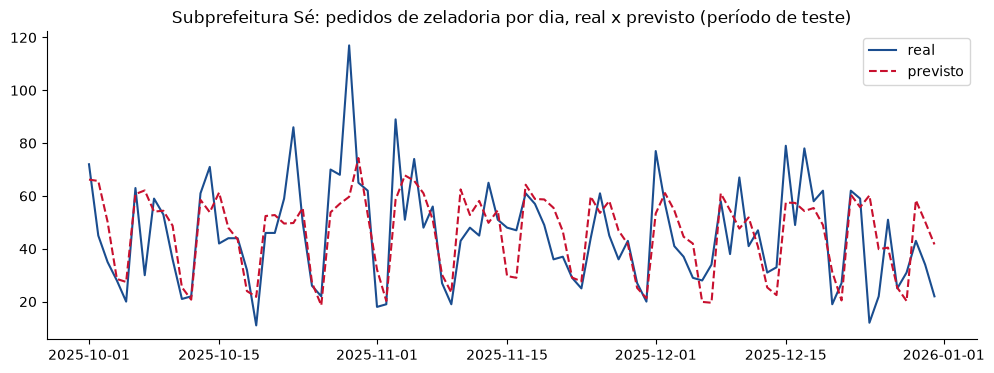

Sé: {'media_real': 45.4, 'erro_medio': 11.1}


In [12]:
se = teste_lin.assign(previsto=previsto).query("subprefeitura == 'SE'")
plt.figure(figsize=(12, 4))
plt.plot(se["data"], se["n"], color=AZUL, label="real")
plt.plot(se["data"], se["previsto"], color=VERMELHO, linestyle="--", label="previsto")
plt.title("Subprefeitura Sé: pedidos de zeladoria por dia, real x previsto (período de teste)")
plt.legend()
plt.show()

erro_sub = (teste_lin.assign(erro=np.abs(teste_lin["n"] - previsto))
            .groupby("subprefeitura").agg(media_real=("n", "mean"), erro_medio=("erro", "mean")).round(1))
print("Sé:", erro_sub.loc["SE"].to_dict())

### Interpretação da regressão linear

**Métricas no teste (out-dez/2025):**

| | MAE | RMSE | R² |
|---|---|---|---|
| Regressão linear | **11,6 pedidos/dia** | 16,5 | **0,56** |
| Referência: repetir a média dos últimos 7 dias | 14,9 | 20,2 | 0,34 |

- **MAE de 11,6:** em média, a previsão erra cerca de 12 pedidos por dia, numa subprefeitura que recebe em média uns 45 pedidos por dia. O erro é **22% menor** que o da regra simples "repetir a média da semana".
- **RMSE de 16,5, maior que o MAE:** existem alguns dias com erros grandes (picos inesperados, feriados). Esses são os dias mais difíceis de prever.
- **R² de 0,56:** o modelo explica pouco mais da metade da variação diária. É útil para planejar, mas não é exato.

**Coeficientes:**
- `media_28d` tem o maior peso (0,50): o "tamanho normal" de cada subprefeitura é a melhor pista.
- `ontem` (0,27) e `semana_passada` (0,14) ajustam a previsão ao momento atual.
- `media_7d` ficou perto de zero porque repete a informação de `ontem` e `semana_passada`, que são medidas muito parecidas.
- **Dia da semana:** em relação à segunda-feira, que é a referência, o sábado tem cerca de **32 pedidos a menos** e o domingo cerca de **31 a menos**. A sexta tem cerca de 15 a menos. A segunda é o dia de maior demanda.

No gráfico da Sé, a previsão acompanha bem o ciclo da semana. Ela erra mais nos picos isolados e nos feriados do fim do ano.

## 6. Regressão logística: o pedido corre risco de não ser resolvido em até 7 dias?

**Unidade de análise:** cada pedido (exceto os cancelados).

**Evento previsto:** `atraso = 1` quando o pedido **não** foi finalizado em até 7 dias (inclui os que continuam abertos).

**Variáveis explicativas**, todas conhecidas no momento em que o pedido é aberto:

| Variável | Significado |
|---|---|
| `assunto` | Tipo de problema |
| `subprefeitura` | Região |
| `meio` | Canal usado |
| `dia_semana` | Dia da semana da abertura |
| `fila_7d` | Pedidos do **mesmo assunto na mesma subprefeitura** nos 7 dias anteriores. Mede o quanto a fila já está cheia e é a variável da nossa hipótese |

In [13]:
pedidos = dados[dados["status"] != "Cancelada"].copy()
pedidos["atraso"] = ~((pedidos["status"] == "Finalizada") & (pedidos["dias_ate_finalizar"] <= 7))
pedidos["atraso"] = pedidos["atraso"].astype(int)

# fila_7d: pedidos do mesmo assunto e subprefeitura nos 7 dias ANTERIORES (shift(1) evita usar o proprio dia)
diario = (pedidos.groupby(["subprefeitura", "assunto", "data_abertura"]).size()
          .unstack(["subprefeitura", "assunto"], fill_value=0)
          .reindex(dias, fill_value=0))
fila = (diario.shift(1).rolling(7, min_periods=1).sum().fillna(0)
        .stack(["subprefeitura", "assunto"], future_stack=True).rename("fila_7d").reset_index()
        .rename(columns={"level_0": "data_abertura"}))
pedidos = pedidos.merge(fila, on=["data_abertura", "subprefeitura", "assunto"], how="left")

treino_log = pedidos[pedidos["data_abertura"] < CORTE]
teste_log = pedidos[pedidos["data_abertura"] >= CORTE]
print(f"Treino: {len(treino_log):,} pedidos | Teste: {len(teste_log):,} pedidos")
print(f"Taxa de atraso: treino {treino_log['atraso'].mean():.1%} | teste {teste_log['atraso'].mean():.1%}")

Treino: 392,514 pedidos | Teste: 112,932 pedidos
Taxa de atraso: treino 30.3% | teste 28.2%


As classes são **desbalanceadas**: cerca de 30% dos pedidos atrasam. Um modelo ingênuo que sempre respondesse "não atrasa" acertaria 70% das vezes e seria inútil. Por isso:
- usamos `class_weight="balanced"`, para que errar um atraso pese tanto quanto errar um pedido no prazo;
- avaliamos com **precisão, recall e F1 da classe "atraso"**, e não só com a acurácia.

In [14]:
CAT_LOG = ["assunto", "subprefeitura", "meio", "dia_semana"]
NUM_LOG = ["fila_7d"]

modelo_logistico = Pipeline([
    ("preparo", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_LOG),
        ("num", StandardScaler(), NUM_LOG),
    ])),
    ("regressao", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
modelo_logistico.fit(treino_log[CAT_LOG + NUM_LOG], treino_log["atraso"])

prob_atraso = modelo_logistico.predict_proba(teste_log[CAT_LOG + NUM_LOG])[:, 1]
previsao = (prob_atraso >= 0.5).astype(int)
real = teste_log["atraso"]

metricas_log = pd.Series({
    "Acurácia": accuracy_score(real, previsao),
    "Precisão (atraso)": precision_score(real, previsao),
    "Recall (atraso)": recall_score(real, previsao),
    "F1 (atraso)": f1_score(real, previsao),
    "AUC (separação geral)": roc_auc_score(real, prob_atraso),
}).round(3)
metricas_log

Acurácia                 0.732
Precisão (atraso)        0.515
Recall (atraso)          0.853
F1 (atraso)              0.642
AUC (separação geral)    0.820
dtype: float64

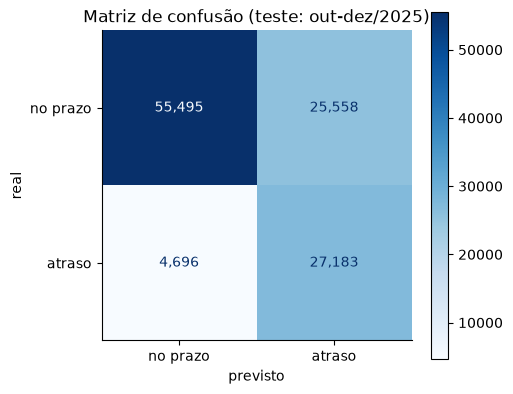

In [15]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(real, previsao), display_labels=["no prazo", "atraso"]).plot(
    ax=ax, cmap="Blues", values_format=",")
ax.set_title("Matriz de confusão (teste: out-dez/2025)")
ax.set_xlabel("previsto")
ax.set_ylabel("real")
plt.show()

In [16]:
# Trade-off entre precisao e recall conforme o limiar de decisao
limiares = [0.3, 0.4, 0.5, 0.6, 0.7]
pd.DataFrame([{
    "limiar": l,
    "precisão": precision_score(real, prob_atraso >= l),
    "recall": recall_score(real, prob_atraso >= l),
    "F1": f1_score(real, prob_atraso >= l),
    "% marcados como risco": (prob_atraso >= l).mean(),
} for l in limiares]).round(3)

,limiar,precisão,recall,F1,% marcados como risco
0,0.3,0.484,0.891,0.628,0.519
1,0.4,0.502,0.874,0.638,0.491
2,0.5,0.515,0.853,0.642,0.467
3,0.6,0.544,0.736,0.626,0.382
4,0.7,0.648,0.456,0.536,0.199


In [17]:
nomes = modelo_logistico.named_steps["preparo"].get_feature_names_out()
coef_log = pd.Series(modelo_logistico.named_steps["regressao"].coef_[0], index=nomes)
razao_chances = np.exp(coef_log).round(2)   # >1 aumenta a chance de atraso; <1 diminui

print("Hipótese - fila_7d (padronizada):", razao_chances["num__fila_7d"])
print()
assuntos = razao_chances[razao_chances.index.str.startswith("cat__assunto_")].sort_values(ascending=False)
assuntos.index = assuntos.index.str.replace("cat__assunto_", "")
print("Razão de chances de atraso por assunto (quanto maior, mais arriscado):")
print(assuntos)

Hipótese - fila_7d (padronizada): 1.12

Razão de chances de atraso por assunto (quanto maior, mais arriscado):
Fiação e Postes                                  65.03
Calçadas, guias e postes                          9.56
Guias rebaixadas                                  5.70
Ruas, vilas, vielas e escadarias                  4.64
Drenagem de água de chuva                         1.97
Capinação e roçada de áreas verdes                1.92
Reparos em Asfalto, Pontes, Viadutos e Túneis     1.63
Praças                                            0.63
Coleta de lixo domiciliar                         0.60
Varrição e limpeza urbana                         0.18
Coleta seletiva                                   0.13
Remoção de grandes objetos                        0.12
Lixeiras Públicas                                 0.11
Ponto viciado, entulho e caçamba de entulho       0.08
dtype: float64


### Interpretação da regressão logística

**Métricas no teste (out-dez/2025), com limiar de 0,5:**
- **Recall de 0,85 (atraso):** o modelo identifica **85% dos pedidos que de fato atrasaram**. Para o nosso uso, esta é a métrica mais importante: deixar passar um pedido que vai atrasar é o erro mais caro.
- **Precisão de 0,52:** de cada 2 pedidos marcados como "risco", 1 de fato atrasou. Há muitos alarmes falsos. É um preço aceitável para um alerta de prioridade, mas não serve para punir ninguém.
- **F1 de 0,64:** é o equilíbrio entre precisão e recall.
- **Acurácia de 0,73 e AUC de 0,82:** o modelo separa bem os pedidos que atrasam dos que não atrasam (AUC de 0,5 seria um sorteio).

**Matriz de confusão:** a maior parte dos erros é de pedidos "no prazo" marcados como risco (falsos positivos). Poucos atrasos passaram despercebidos (falsos negativos).

**O limiar é uma escolha de gestão:**
- **0,4:** o modelo pega ainda mais atrasos (87%), com mais alarmes.
- **0,7:** só 20% dos pedidos são marcados, com precisão de 65%. Isso serve quando a equipe só consegue olhar poucos casos.

**Razões de chance (exp do coeficiente):**
- **Hipótese confirmada.** Cada desvio-padrão a mais na `fila_7d` (pedidos do mesmo tipo na mesma região na semana anterior) multiplica a chance de atraso por **1,12**: com a fila cheia, o risco de atraso aumenta.
- **Assunto é o que mais pesa:**
  - **Calçadas, guias e postes** têm chance de atraso cerca de **9,6 vezes** maior que a referência.
  - **Fiação e postes** têm 65 vezes maior, mas com poucos pedidos.
  - **Entulho** tem 0,08, ou seja, quase sempre é resolvido rápido.
  - **Obras** (calçada, guia, drenagem, asfalto) atrasam. **Limpeza** (entulho, varrição, lixeira) é resolvida rápido.

**Atenção:** como usamos `class_weight="balanced"`, as probabilidades ficam "inflacionadas", maiores que a taxa real de atraso. Elas devem ser lidas como uma **ordem de risco** (qual pedido é mais arriscado), e não como uma probabilidade exata. Por exemplo, na Sé, "capinação" tem risco previsto de 0,64, mas o atraso real foi de 0,27.

## 7. Usando as previsões para decidir

In [18]:
risco = (teste_log.assign(prob_atraso=prob_atraso)
         .groupby(["subprefeitura", "assunto"])
         .agg(pedidos=("atraso", "size"), risco_previsto=("prob_atraso", "mean"), atraso_real=("atraso", "mean"))
         .query("pedidos >= 100")
         .sort_values("risco_previsto", ascending=False))
print("Combinações região + assunto com MAIOR risco previsto de atraso (out-dez/2025, mínimo de 100 pedidos):")
risco.head(10).round(2)

Combinações região + assunto com MAIOR risco previsto de atraso (out-dez/2025, mínimo de 100 pedidos):


,,pedidos,risco_previsto,atraso_real
subprefeitura,assunto,,,
PIRITUBA-JARAGUA,Fiação e Postes,174,0.99,1.00
LAPA,"Calçadas, guias e postes",305,0.95,0.86
PIRITUBA-JARAGUA,"Calçadas, guias e postes",507,0.94,0.88
ITAIM PAULISTA,"Calçadas, guias e postes",308,0.94,0.90
PINHEIROS,"Calçadas, guias e postes",461,0.93,0.89
BUTANTA,"Calçadas, guias e postes",343,0.93,0.69
PENHA,"Calçadas, guias e postes",363,0.93,0.91
CAMPO LIMPO,"Calçadas, guias e postes",635,0.91,0.91
VILA MARIANA,"Calçadas, guias e postes",327,0.91,0.76


In [19]:
print("Sé (Liberdade) - risco previsto por assunto:")
risco.loc["SE"].sort_values("risco_previsto", ascending=False).round(2)

Sé (Liberdade) - risco previsto por assunto:


,pedidos,risco_previsto,atraso_real
assunto,,,
"Calçadas, guias e postes",526,0.90,0.87
Drenagem de água de chuva,556,0.65,0.68
Capinação e roçada de áreas verdes,112,0.64,0.27
"Reparos em Asfalto, Pontes, Viadutos e Túneis",784,0.62,0.55
Coleta de lixo domiciliar,121,0.35,0.31
Varrição e limpeza urbana,483,0.14,0.01
Lixeiras Públicas,271,0.09,0.00
"Ponto viciado, entulho e caçamba de entulho",1156,0.08,0.03


In [20]:
# Previsao para o primeiro dia util depois do fim da base, com o modelo linear treinado
ultimo = demanda[demanda["data"] == demanda["data"].max()]
hist = demanda.set_index(["subprefeitura", "data"])["n"]
proximo = pd.DataFrame({"subprefeitura": subprefeituras})
proximo["ontem"] = [hist[(s, pd.Timestamp("2025-12-31"))] for s in subprefeituras]
proximo["semana_passada"] = [hist[(s, pd.Timestamp("2025-12-26"))] for s in subprefeituras]
proximo["media_7d"] = [hist[s].loc["2025-12-25":"2025-12-31"].mean() for s in subprefeituras]
proximo["media_28d"] = [hist[s].loc["2025-12-04":"2025-12-31"].mean() for s in subprefeituras]
proximo["dia_semana"] = "sex"   # 02/01/2026
proximo["previsto"] = modelo_linear.predict(proximo[NUM_LIN + CAT_LIN]).round(0)
print("Previsão de pedidos de zeladoria para sexta, 02/01/2026 (maiores subprefeituras):")
proximo.sort_values("previsto", ascending=False).head(8)[["subprefeitura", "previsto"]]

Previsão de pedidos de zeladoria para sexta, 02/01/2026 (maiores subprefeituras):


,subprefeitura,previsto
12,ITAQUERA,63.0
15,LAPA,57.0
2,CAMPO LIMPO,53.0
19,PENHA,53.0
3,CAPELA DO SOCORRO,52.0
1,BUTANTA,46.0
10,IPIRANGA,45.0
22,PIRITUBA-JARAGUA,44.0


### Recomendações

**1. Mostrar ao cidadão o risco de atraso no momento do registro (CitizenTech).**
Quando o morador registra o problema, o app pode avisar se ele costuma ser resolvido em poucos dias (entulho, varrição) ou se há risco de demora (calçada, drenagem). Isso **troca a incerteza por uma expectativa honesta** e reduz pedidos repetidos de quem acha que foi esquecido.

**2. Fila do gestor: priorizar os pedidos de alto risco.**
Com limiar de 0,5, o gestor recebe uma lista com 85% dos pedidos que iam atrasar. Na **Sé (Liberdade)**, os assuntos de maior risco são:

| Assunto | Atraso real (out-dez/2025) |
|---|---|
| Calçadas, guias e postes | 87% |
| Drenagem | 68% |
| Asfalto | 55% |

O bueiro da Rua Barão de Iguape, 288, que encontramos na visita, se encaixa exatamente nesse grupo.

**3. Separar "obra" de "limpeza" no planejamento.**
Calçadas, guias e drenagem atrasam em quase toda a cidade. Das 10 combinações região + assunto de maior risco, 9 são de calçadas, guias e postes, e a outra é de fiação e postes. Isso indica falta de capacidade para **obras** e não para limpeza. A recomendação é um **mutirão ou contrato específico para calçadas**, começando por Pirituba-Jaraguá, Lapa, Itaim Paulista e Pinheiros, onde de 86% a 90% desses pedidos atrasaram.

**4. Dimensionar as equipes pela previsão de demanda.**
A regressão linear prevê quantos pedidos cada subprefeitura vai receber, com erro médio de cerca de 12 por dia. Na prática:
- **reforçar a segunda-feira**, o dia de pico, e o começo da semana;
- deslocar folgas para o fim de semana, que tem cerca de 30 pedidos a menos por subprefeitura;
- quando a fila do mesmo assunto crescer, antecipar a equipe, porque a fila cheia aumenta o risco de atraso.

**5. Monitorar mensalmente.**
Os dois modelos devem ser re-treinados com os dados novos do SP156, publicados a cada trimestre, e conferidos com as métricas deste notebook.

### Limitações
- **Pedido não é problema.** O SP156 conta pedidos registrados, não problemas existentes. Bairros onde as pessoas reclamam menos (por falta de acesso digital, por exemplo) parecem ter menos problemas do que têm. Isso pode **esconder desigualdades**, e a CitizenTech deve facilitar o registro nessas regiões.
- **Não sabemos o tamanho das equipes** de cada subprefeitura nem o orçamento. O atraso pode ser falta de gente, e não algo que o modelo consiga ver.
- **"Finalizada" nem sempre quer dizer resolvida.** O órgão pode encerrar o pedido sem consertar, e os dados não mostram isso.
- **Correlação, não causa.** O modelo mostra que calçadas atrasam, mas não explica por quê.
- **Período curto e mudanças no tempo.** Usamos só 2025. Feriados, chuvas e mudanças de contrato alteram o padrão. Por isso, a divisão por data e o re-treino periódico são necessários.
- **Probabilidades não calibradas** (veja a interpretação da logística): servem para ordenar os pedidos, não como chance exata.

### Impactos esperados
- **Para o cidadão:** saber em quanto tempo o problema costuma ser resolvido e ver seus pedidos de maior risco priorizados. O impacto é maior para idosos e pessoas com deficiência, que mais sofrem com calçadas quebradas, justamente o assunto de maior atraso.
- **Para a subprefeitura:** antecipar a demanda e agir antes do atraso, em vez de reagir a reclamações repetidas.
- **Indicador:** acompanhar mês a mês o **% de pedidos resolvidos em até 7 dias**, que foi de 72% no teste. A meta é subir esse número nas regiões e assuntos de maior risco.
- **ODS 11** (cidades sustentáveis) e **ODS 10** (redução das desigualdades), ao direcionar recursos para onde o atraso é maior.